# T10. Limpieza de los viajes

**Objetivo.** Decidir qué viajes del CSV original entran en el análisis con umbrales justificados con datos, y con una excepción para los viajes con paradas (apartado 4). No se borra ningún viaje: los no válidos quedan con `elegible = False` y sus reglas incumplidas en `motivo`.

**Valor para el proyecto.** Todas las fases (matrices OD, estaciones, flota, consumo y recarga) parten de estos viajes. Si se cuelan desbloqueos sin viaje o viajes sin cerrar, inflan la demanda y la energía; si se quita demasiado, la red se diseña para menos demanda de la real.

Los umbrales están en `config.yaml` (`limpieza`). Se revisan con el periodo de ajuste (1–21/02) y se aplican igual a la semana reservada (22–28/02). Este notebook genera `datos/procesados/viajes_limpios.parquet`, las tablas `T10_*` de `resultados/tablas/exploracion/`, las figuras `T10_*` y los datos de la web.

In [1]:
import numpy as np
import pandas as pd
import h3
from IPython.display import display

from comun import limpieza
from comun.config import cargar_config, carpeta_tablas, ruta
from comun.datos import generar_viajes_limpios
from comun.figuras import guardar_figura, plt
from comun.geo import haversine_m
from comun.web import exportar

TEMA, FASE = "exploracion", "fase0"
TABLAS = carpeta_tablas(TEMA)
CFG = cargar_config()
U = limpieza.umbrales()

def tabla_indicadores(filas):
    # Tabla indicador/valor que conserva los enteros como enteros en el CSV.
    return pd.DataFrame({"indicador": [k for k, _ in filas],
                         "valor": pd.Series([v for _, v in filas], dtype=object)})

## 1. Comprobaciones estructurales y embudo de limpieza

**Qué queremos ver.** Si el CSV tiene errores de estructura (nulos, duplicados, duraciones, velocidades o precios que no cuadran, puntos fuera de Roma, viajes solapados del mismo patinete) y cuántos viajes quita cada regla aplicada en orden.

**Por qué importa.** Si los datos son coherentes, solo hay que decidir umbrales de comportamiento. La tabla de embudo es la que va a la memoria para que se pueda auditar cada viaje excluido.

In [2]:
viajes, embudo, recuento = generar_viajes_limpios()
embudo.to_csv(TABLAS / "T10_embudo.csv", index=False)
recuento.to_csv(TABLAS / "T10_recuento_motivos.csv", index=False)

periodos = (viajes.groupby("periodo")
            .agg(viajes=("trip_id", "size"), elegibles=("elegible", "sum"))
            .reset_index())
periodos["porcentaje_elegibles"] = (100 * periodos["elegibles"] / periodos["viajes"]).round(2)
periodos.to_csv(TABLAS / "T10_viajes_por_periodo.csv", index=False)

exportar(FASE, "t10_embudo", {"pasos": embudo, "recuento": recuento, "periodos": periodos})
display(embudo, recuento, periodos)

,paso,regla,descripcion,excluidos,quedan
0,0,inicial,Viajes del CSV original,0,25186
1,1,nulos,Algún campo vacío,0,25186
2,2,duplicado,Mismo patinete y misma salida que otro viaje,0,25186
3,3,tiempos_incoherentes,tsD - tsO distinto de tt (±1 s) o tt <= 0,0,25186
4,4,velocidad_incoherente,"vel distinta de 3,6·dis/tt (±0.01 km/h)",0,25186
5,5,precio_incoherente,Precio distinto de la tarifa (±0.01 €),0,25186
6,6,fuera_de_zona,Algún extremo fuera del rectángulo de servicio,0,25186
7,7,solape,Empieza antes de que acabe el viaje anterior d...,0,25186
8,8,tt_largo,Duración > 7200 s (salvo viaje con paradas: >=...,112,25074
9,9,vel_alta,Velocidad > 25 km/h,2,25072


,motivo,viajes,unico_motivo,porcentaje
0,nulos,0,0,0.00
1,duplicado,0,0,0.00
2,tiempos_incoherentes,0,0,0.00
3,velocidad_incoherente,0,0,0.00
4,precio_incoherente,0,0,0.00
5,fuera_de_zona,0,0,0.00
6,solape,0,0,0.00
7,tt_largo,112,2,0.44
8,vel_alta,2,1,0.01
9,tt_corto,950,157,3.77


,periodo,viajes,elegibles,porcentaje_elegibles
0,ajuste,18004,16756,93.07
1,reservada,7182,6614,92.09


**Conclusiones.**

- Los datos son estructuralmente limpios: ninguna de las siete comprobaciones estructurales falla. El precio es exactamente `1 € + 0,15 €/min` y la velocidad `3,6 · dis / tt` en todos los viajes.
- Solo se excluyen viajes por comportamiento: 112 de más de 2 h, 2 de más de 25 km/h, 949 de menos de 60 s, 596 más de menos de 100 m y 157 más de menos de 2 km/h. Las dos reglas de 2 h y 2 km/h no se aplican a los 78 viajes con paradas del apartado 4.
- Quedan **23 370 viajes elegibles (92,8 %)**: 16 756 en el ajuste (93,1 %) y 6 614 en la semana reservada (92,1 %). Los dos periodos pierden una proporción parecida, así que la limpieza no sesga la validación.

## 2. Distribuciones de duración, distancia y velocidad con los umbrales

**Qué queremos ver.** Dónde caen los umbrales respecto a la forma de cada distribución: si cortan colas o picos anómalos o si se meten en la parte central de los viajes normales.

**Por qué importa.** Un umbral es defendible si separa dos poblaciones distintas (desbloqueos frente a viajes, viajes cerrados frente a olvidados). Si cortara por la mitad de la distribución, estaríamos quitando demanda real.

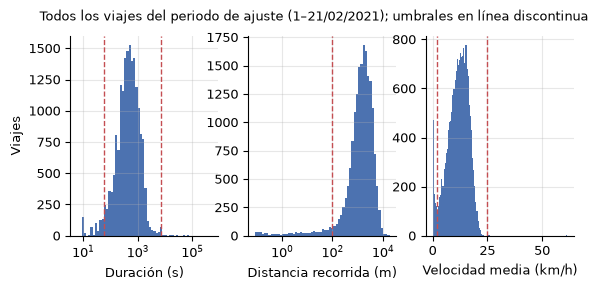

In [3]:
ajuste = viajes[viajes["periodo"] == "ajuste"]
paneles = {
    "tt_s": ("Duración (s)", [U["tt_min_s"], U["tt_max_s"]], "log"),
    "dis_m": ("Distancia recorrida (m)", [U["dis_min_m"]], "log"),
    "vel_kmh": ("Velocidad media (km/h)", [U["vel_min_kmh"], U["vel_max_kmh"]], "lineal"),
}
histogramas = {}
fig, ejes = plt.subplots(1, 3, figsize=(6.5, 2.6))
for eje, (col, (etiqueta, lineas, escala)) in zip(ejes, paneles.items()):
    if escala == "log":
        valores = ajuste[col][ajuste[col] > 0]
        bordes = np.logspace(np.log10(valores.min()), np.log10(valores.max()), 61)
    else:
        valores = ajuste[col]
        bordes = np.arange(0, valores.max() + 0.5, 0.5)
    cuentas, _ = np.histogram(valores, bins=bordes)
    histogramas[col] = {"etiqueta": etiqueta, "escala": escala, "bordes": bordes.round(4),
                        "cuentas": cuentas, "umbrales": lineas,
                        "fuera_de_escala": int(len(ajuste) - cuentas.sum())}
    eje.stairs(cuentas, bordes, fill=True, color="#4C72B0")
    if escala == "log":
        eje.set_xscale("log")
    for u in lineas:
        eje.axvline(u, color="#C44E52", lw=1, ls="--")
    eje.set_xlabel(etiqueta)
ejes[0].set_ylabel("Viajes")
fig.suptitle("Todos los viajes del periodo de ajuste (1–21/02/2021); umbrales en línea discontinua", fontsize=9)
guardar_figura(fig, TEMA, "T10_umbrales")
exportar(FASE, "t10_histogramas", {"n_viajes": len(ajuste), "variables": histogramas})

**Conclusiones.**

- Duración: casi todos los viajes duran entre 2 y 30 minutos. Los 60 s dejan fuera un grupo pequeño de desbloqueos de pocos segundos y las 2 h, una cola larga y casi plana.
- Distancia: por debajo de 100 m hay una cola larga y plana que llega a menos de 1 m (patinetes que casi no se mueven). La distribución principal empieza a subir justo a partir del corte de 100 m.
- Velocidad: hay un pico junto a 0 km/h y un valle hacia los 2 km/h antes de la distribución principal (mediana de unos 12 km/h). El límite de 25 km/h coincide con la velocidad máxima del patinete y solo afecta a 2 viajes.

## 3. Los viajes casi parados

**Qué queremos ver.** Qué son los ~1 000 viajes del pico de velocidad cercana a 0 y si las reglas de duración y distancia ya los quitan o hace falta una regla propia.

**Por qué importa.** Un viaje a 1 km/h que recorre 500 m ocupa el patinete durante media hora. En la simulación de flota inflaría el tiempo de uso y en la de consumo no cambiaría la energía, así que hay que decidir explícitamente qué hacer con ellos.

In [4]:
lentos = viajes[viajes["vel_kmh"] < 1]
solo_vel_baja = viajes[viajes["motivo"] == "vel_baja"]
resumen_lentos = tabla_indicadores([
    ("viajes con velocidad < 1 km/h", len(lentos)),
    ("  excluidos también por otras reglas", int((~lentos["motivo"].isin(["", "vel_baja"])).sum())),
    ("  que solo excluye vel_baja", int((lentos["motivo"] == "vel_baja").sum())),
    ("  elegibles como viaje con paradas (apartado 4)", int(lentos["elegible"].sum())),
    ("viajes que solo excluye vel_baja (< 2 km/h)", len(solo_vel_baja)),
    ("  distancia mediana (m)", round(solo_vel_baja["dis_m"].median(), 1)),
    ("  duración mediana (min)", round(solo_vel_baja["tt_s"].median() / 60, 1)),
    ("  porcentaje que dura más de 20 min", round(100 * (solo_vel_baja["tt_s"] > 1200).mean(), 1)),
])
resumen_lentos.to_csv(TABLAS / "T10_viajes_lentos.csv", index=False)
exportar(FASE, "t10_lentos", resumen_lentos)
display(resumen_lentos)

,indicador,valor
0,viajes con velocidad < 1 km/h,976
1,excluidos también por otras reglas,894
2,que solo excluye vel_baja,60
3,elegibles como viaje con paradas (apartado 4),22
4,viajes que solo excluye vel_baja (< 2 km/h),157
5,distancia mediana (m),318.1
6,duración mediana (min),19.7
7,porcentaje que dura más de 20 min,47.8


**Conclusiones.**

- El pico de ~1 000 viajes por debajo de 1 km/h son desbloqueos sin recorrido: 894 de los 976 ya caen por duración o distancia, y otros 22 son viajes con paradas de más de 1 km (apartado 4).
- Los 157 que solo excluye la regla nueva `vel_baja` recorren poco (mediana de 318 m) y duran mucho para esa distancia (mediana de 19,7 min). Son patinetes que no se cerraron a tiempo o que se llevaron a mano, no desplazamientos en patinete.
- Se añade `vel_baja` con umbral de 2 km/h, en el valle del histograma. Cuesta el 0,7 % de la demanda y se comprueba en el apartado 6 que no cambia las conclusiones.

## 4. Viajes lentos o largos con recorrido real

**Qué queremos ver.** Si entre los viajes que quitan `vel_baja` o `tt_largo` hay desplazamientos reales: viajes que recorren una distancia normal en patinete, pero con paradas a mitad de camino (el usuario mantiene la reserva mientras entra en una tienda o se para en un monumento) y por eso salen lentos o largos.

**Por qué importa.** Un patinete olvidado sin cerrar no se mueve, y su viaje no es demanda. Un viaje con paradas sí lo es: tiene un origen y un destino reales y, si se descarta, la red pierde demanda en las zonas donde ocurre. La excepción está en `config.yaml` (`limpieza.viaje_con_paradas`): un viaje de al menos 1 000 m puede incumplir **una** de las dos reglas, no las dos. Si es lento, debe durar como mucho 2 h; si es largo, debe ir a 2 km/h o más y durar como mucho 2,5 h. Los que son a la vez largos y lentos siguen fuera.

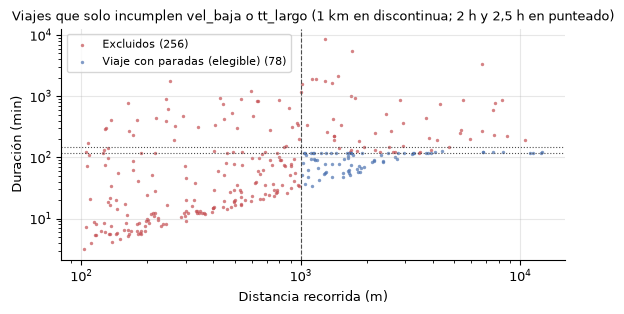

,grupo,viajes,dis_m_mediana,tt_min_mediana,tt_min_maxima,vel_kmh_mediana,recta_m_mediana,recta_500m_o_mas_pc,rodeo_mediano,fin_de_semana_pc
0,lentos con paradas (rescatados de vel_baja),68,1635.8,91.0,119.8,1.35,781.9,61.8,2.03,30.9
1,largos con paradas (rescatados de tt_largo),10,7928.2,120.5,126.5,3.95,1553.3,80.0,5.24,50.0
2,largos y lentos de al menos 1 km (siguen fuera),52,2379.2,266.8,8560.0,0.58,452.7,48.1,6.48,42.3
3,resto de viajes elegibles,23292,1634.2,8.2,120.0,12.48,955.7,75.1,1.36,28.4


In [5]:
P = U["viaje_con_paradas"]
paradas = limpieza.con_paradas(viajes, U)
recta = pd.Series(haversine_m(viajes["latO"], viajes["lonO"], viajes["latD"], viajes["lonD"]), index=viajes.index)
finde = viajes["tsO"].dt.day_of_week >= 5
grupos = {
    "lentos con paradas (rescatados de vel_baja)": paradas & (viajes["vel_kmh"] < U["vel_min_kmh"]),
    "largos con paradas (rescatados de tt_largo)": paradas & (viajes["tt_s"] > U["tt_max_s"]),
    "largos y lentos de al menos 1 km (siguen fuera)": (viajes["tt_s"] > U["tt_max_s"])
        & (viajes["vel_kmh"] < U["vel_min_kmh"]) & (viajes["dis_m"] >= P["dis_min_m"]),
    "resto de viajes elegibles": viajes["elegible"] & ~paradas,
}
filas = []
for nombre, m in grupos.items():
    g = viajes[m]
    filas.append({
        "grupo": nombre, "viajes": int(m.sum()),
        "dis_m_mediana": round(g["dis_m"].median(), 1),
        "tt_min_mediana": round(g["tt_s"].median() / 60, 1),
        "tt_min_maxima": round(g["tt_s"].max() / 60, 1),
        "vel_kmh_mediana": round(g["vel_kmh"].median(), 2),
        "recta_m_mediana": round(recta[m].median(), 1),
        "recta_500m_o_mas_pc": round(100 * (recta[m] >= 500).mean(), 1),
        "rodeo_mediano": round((g["dis_m"] / recta[m].clip(lower=1)).median(), 2),
        "fin_de_semana_pc": round(100 * finde[m].mean(), 1),
    })
tabla_paradas = pd.DataFrame(filas)
tabla_paradas.to_csv(TABLAS / "T10_viajes_con_paradas.csv", index=False)

# Viajes que quitaría vel_baja o tt_largo sin la excepción y que no caen por otra regla.
otras = viajes["motivo"].fillna("").str.split(";").apply(lambda r: [x for x in r if x not in ("", "vel_baja", "tt_largo")])
candidatos = viajes[((viajes["vel_kmh"] < U["vel_min_kmh"]) | (viajes["tt_s"] > U["tt_max_s"])) & (otras.str.len() == 0)]
fig, eje = plt.subplots(figsize=(6.5, 3.0))
for etiqueta, m, color in [("Excluidos", ~paradas.loc[candidatos.index], "#C44E52"),
                           ("Viaje con paradas (elegible)", paradas.loc[candidatos.index], "#4C72B0")]:
    c = candidatos[m]
    eje.scatter(c["dis_m"], c["tt_s"] / 60, s=6, color=color, alpha=0.7, lw=0, label=f"{etiqueta} ({len(c)})")
eje.set_xscale("log")
eje.set_yscale("log")
eje.axvline(P["dis_min_m"], color="0.3", lw=0.8, ls="--")
for t in (U["tt_max_s"], P["tt_max_s"]):
    eje.axhline(t / 60, color="0.3", lw=0.8, ls=":")
eje.set_xlabel("Distancia recorrida (m)")
eje.set_ylabel("Duración (min)")
eje.set_title("Viajes que solo incumplen vel_baja o tt_largo (1 km en discontinua; 2 h y 2,5 h en punteado)", fontsize=9)
eje.legend(fontsize=8, loc="upper left")
guardar_figura(fig, TEMA, "T10_viajes_con_paradas")

exportar(FASE, "t10_paradas", {
    "umbrales": {"dis_min_m": P["dis_min_m"], "tt_max_s": U["tt_max_s"], "tt_max_paradas_s": P["tt_max_s"],
                 "vel_min_kmh": U["vel_min_kmh"]},
    "grupos": tabla_paradas,
    "puntos": {"dis_m": candidatos["dis_m"].round(1), "tt_min": (candidatos["tt_s"] / 60).round(2),
               "con_paradas": paradas.loc[candidatos.index]},
})
display(tabla_paradas)

**Conclusiones.**

- La excepción recupera **78 viajes** (+0,3 % de la demanda): 68 lentos y 10 largos. Con ella quedan 23 370 viajes elegibles en lugar de 23 292.
- Los 68 lentos recorren lo mismo que un viaje normal (mediana de 1 636 m frente a 1 634 m) y se desplazan de verdad: acaban a 782 m en línea recta de donde salieron (mediana), y el 62 % a más de 500 m. Lo que los separa del resto es que duran 91 min en vez de 8 y dan más rodeo (2,0 veces la línea recta frente a 1,4). Encaja con paseos o recados con paradas, no con un patinete olvidado, que no se movería.
- Los 10 largos duran entre 2 h 0 min y 2 h 7 min y recorren de 4,1 a 12,6 km a entre 2 y 6 km/h: van en marcha casi todo el tiempo y solo pasan el corte de 2 h por unos minutos.
- Los 52 viajes de al menos 1 km que son a la vez largos y lentos siguen fuera. Duran 4 h 27 min de mediana (hasta 143 h) a 0,6 km/h, y la mitad acaba a menos de 500 m del origen: son patinetes que no se cerraron.
- El límite de 1 km es un criterio prudente, no un corte natural: en la figura, justo a la izquierda hay viajes lentos parecidos que siguen fuera. Con 500 m se recuperarían 117 viajes lentos en vez de 68 (+0,2 % más de demanda), así que la elección no cambia las conclusiones.
- Su reparto entre laborables y fin de semana es parecido al del resto (31 % frente a 28 % en fin de semana), así que no cambian el perfil temporal.
- Limitación: sin trayectorias no se pueden ver las paradas; la excepción se apoya en la distancia recorrida y en el desplazamiento entre origen y destino.

## 5. Sensibilidad de cada umbral

**Qué queremos ver.** Cuántos viajes del periodo de ajuste excluiría cada umbral por sí solo al moverlo, y si el valor elegido está en una zona estable o en una pendiente fuerte.

**Por qué importa.** Si un pequeño cambio de umbral moviera muchos viajes, la decisión sería frágil y habría que justificarla mejor o revisar su efecto en los resultados.

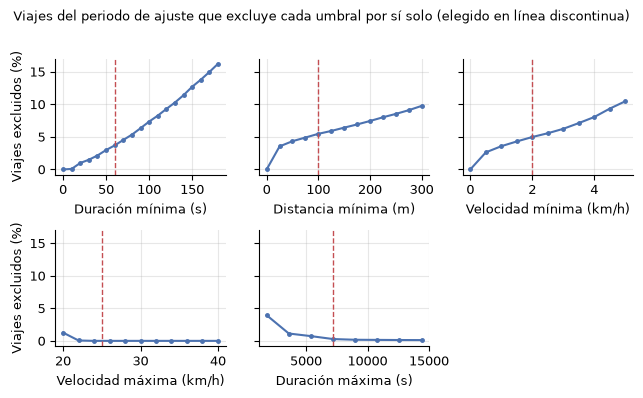

parametro,dis_min_m,tt_max_s,tt_min_s,vel_max_kmh,vel_min_kmh
umbral,,,,,
0.0,0.00,NaN,0.00,NaN,0.00
0.5,NaN,NaN,NaN,NaN,2.62
1.0,NaN,NaN,NaN,NaN,3.57
1.5,NaN,NaN,NaN,NaN,4.30
2.0,NaN,NaN,NaN,NaN,4.98
2.5,NaN,NaN,NaN,NaN,5.56
3.0,NaN,NaN,NaN,NaN,6.24
3.5,NaN,NaN,NaN,NaN,7.12
4.0,NaN,NaN,NaN,NaN,8.05


In [6]:
BARRIDOS = {
    "tt_min_s": ("tt_s", "menor", list(range(0, 181, 10)), "Duración mínima (s)"),
    "dis_min_m": ("dis_m", "menor", list(range(0, 301, 25)), "Distancia mínima (m)"),
    "vel_min_kmh": ("vel_kmh", "menor", [x / 2 for x in range(0, 11)], "Velocidad mínima (km/h)"),
    "vel_max_kmh": ("vel_kmh", "mayor", list(range(20, 41, 2)), "Velocidad máxima (km/h)"),
    "tt_max_s": ("tt_s", "mayor", list(range(1800, 14401, 1800)), "Duración máxima (s)"),
}
filas = []
for parametro, (col, sentido, valores, _) in BARRIDOS.items():
    for v in valores:
        fuera = (ajuste[col] < v) if sentido == "menor" else (ajuste[col] > v)
        filas.append({"parametro": parametro, "umbral": v, "excluidos": int(fuera.sum()),
                      "porcentaje": round(100 * fuera.mean(), 2)})
sens = pd.DataFrame(filas)
sens.to_csv(TABLAS / "T10_sensibilidad_umbrales.csv", index=False)

fig, ejes = plt.subplots(2, 3, figsize=(6.5, 4.0), sharey=True)
ejes = ejes.ravel()
for eje, (parametro, (_, _, _, etiqueta)) in zip(ejes, BARRIDOS.items()):
    t = sens[sens["parametro"] == parametro]
    eje.plot(t["umbral"], t["porcentaje"], marker="o", ms=2.5, color="#4C72B0")
    eje.axvline(U[parametro], color="#C44E52", lw=1, ls="--")
    eje.set_xlabel(etiqueta)
ejes[-1].set_visible(False)
for eje in ejes[::3]:
    eje.set_ylabel("Viajes excluidos (%)")
fig.suptitle("Viajes del periodo de ajuste que excluye cada umbral por sí solo (elegido en línea discontinua)", fontsize=9)
fig.tight_layout(rect=(0, 0, 1, 0.96))
guardar_figura(fig, TEMA, "T10_sensibilidad_umbrales")

exportar(FASE, "t10_sensibilidad", {
    p: {"etiqueta": etiqueta, "elegido": U[p], "umbral": sens.loc[sens.parametro == p, "umbral"],
        "excluidos": sens.loc[sens.parametro == p, "excluidos"],
        "porcentaje": sens.loc[sens.parametro == p, "porcentaje"]}
    for p, (_, _, _, etiqueta) in BARRIDOS.items()
})
display(sens.pivot_table(index="umbral", columns="parametro", values="porcentaje"))

**Conclusiones.**

- Duración mínima: la curva sube sin codo. 60 s es el criterio natural de "menos de un minuto no es un viaje" y excluye por sí solo el 3,7 %.
- Distancia mínima: el salto está por debajo de 25 m (3,5 %); a partir de ahí la curva es casi lineal, así que 100 m o 50 m cambian poco.
- Velocidad mínima: la curva sube suave; 2 km/h excluye el 5,0 % por sí solo, pero casi todos ya caen por las reglas anteriores.
- Velocidad y duración máximas: las curvas se aplanan antes del umbral elegido (25 km/h y 2 h), así que son decisiones estables.

## 6. Limpieza permisiva frente a la principal

**Qué queremos ver.** Si una limpieza menos restrictiva (30 s, 50 m, sin velocidad mínima, 30 km/h y 3 h) cambia los indicadores que usarán las fases siguientes: volumen, distancias, duraciones, kilómetros, energía y concentración espacial.

**Por qué importa.** Es la prueba de robustez de la limpieza. Si los indicadores apenas cambian, las conclusiones del proyecto no dependen de los umbrales y se puede decir en la memoria.

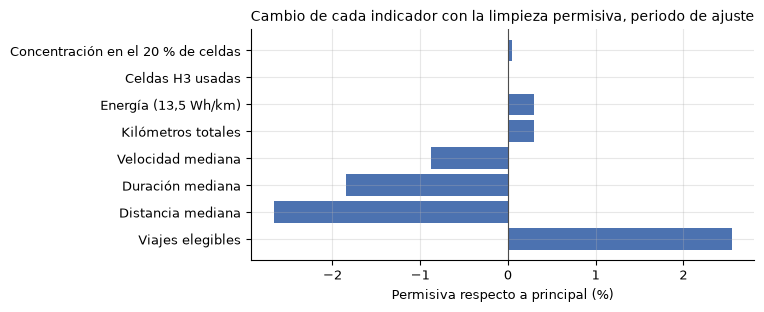

,limpieza,periodo,viajes_elegibles,porcentaje_elegibles,dis_m_mediana,tt_s_mediana,vel_kmh_mediana,km_totales,energia_kwh_13_5,celdas_h3_res8,extremos_en_20pc_celdas_pc
0,principal,ajuste,16756,93.07,1619.4,490.0,12.46,34430.6,464.8,111,56.91
1,principal,reservada,6614,92.09,1671.3,500.0,12.47,14103.6,190.4,108,54.99
2,permisiva,ajuste,17183,95.44,1576.2,481.0,12.35,34533.0,466.2,111,56.94
3,permisiva,reservada,6782,94.43,1628.6,491.0,12.34,14151.4,191.0,109,54.94


,diferencia_pc
viajes_elegibles,2.55
dis_m_mediana,-2.67
tt_s_mediana,-1.84
vel_kmh_mediana,-0.88
km_totales,0.30
energia_kwh_13_5,0.30
celdas_h3_res8,0.00
extremos_en_20pc_celdas_pc,0.05


In [7]:
def indicadores(v, nombre):
    consumo = CFG["patinete"]["consumo_wh_km"]
    res = CFG["exploracion"]["resoluciones_h3"][0]
    filas = []
    for periodo, grupo in v.groupby("periodo"):
        e = grupo[grupo["elegible"]]
        celdas = pd.Series(
            [h3.latlng_to_cell(a, b, res) for a, b in zip(e["latO"], e["lonO"])]
            + [h3.latlng_to_cell(a, b, res) for a, b in zip(e["latD"], e["lonD"])]
        ).value_counts()
        n_top = max(1, int(np.ceil(0.2 * len(celdas))))
        filas.append({
            "limpieza": nombre, "periodo": periodo,
            "viajes_elegibles": len(e),
            "porcentaje_elegibles": round(100 * len(e) / len(grupo), 2),
            "dis_m_mediana": round(e["dis_m"].median(), 1),
            "tt_s_mediana": round(e["tt_s"].median(), 1),
            "vel_kmh_mediana": round(e["vel_kmh"].median(), 2),
            "km_totales": round(e["dis_m"].sum() / 1000, 1),
            "energia_kwh_13_5": round(e["dis_m"].sum() / 1000 * consumo / 1000, 1),
            f"celdas_h3_res{res}": len(celdas),
            "extremos_en_20pc_celdas_pc": round(100 * celdas.iloc[:n_top].sum() / celdas.sum(), 2),
        })
    return filas

permisiva, embudo_permisivo, _ = limpieza.limpiar(limpieza.leer_bruto(ruta("csv_bruto")), "permisiva")
embudo_permisivo.to_csv(TABLAS / "T10_embudo_permisiva.csv", index=False)
comparacion = pd.DataFrame(indicadores(viajes, "principal") + indicadores(permisiva, "permisiva"))
comparacion.to_csv(TABLAS / "T10_comparacion_limpiezas.csv", index=False)

a = comparacion[comparacion["periodo"] == "ajuste"].set_index("limpieza").drop(columns="periodo")
diferencia = ((a.loc["permisiva"] / a.loc["principal"] - 1) * 100).round(2).rename("diferencia_pc")
diferencia = diferencia.drop("porcentaje_elegibles")
NOMBRES = {"viajes_elegibles": "Viajes elegibles", "dis_m_mediana": "Distancia mediana",
           "tt_s_mediana": "Duración mediana", "vel_kmh_mediana": "Velocidad mediana",
           "km_totales": "Kilómetros totales", "energia_kwh_13_5": "Energía (13,5 Wh/km)",
           "celdas_h3_res8": "Celdas H3 usadas", "extremos_en_20pc_celdas_pc": "Concentración en el 20 % de celdas"}

fig, eje = plt.subplots(figsize=(6.5, 3.0))
eje.barh([NOMBRES[k] for k in diferencia.index], diferencia.to_numpy(), color="#4C72B0")
eje.axvline(0, color="0.3", lw=0.8)
eje.set_xlabel("Permisiva respecto a principal (%)")
eje.set_title("Cambio de cada indicador con la limpieza permisiva, periodo de ajuste")
guardar_figura(fig, TEMA, "T10_comparacion_limpiezas")

exportar(FASE, "t10_comparacion", {
    "umbrales": {nombre: {k: limpieza.umbrales(nombre)[k] for k in BARRIDOS} for nombre in ("principal", "permisiva")},
    "indicadores": comparacion,
    "diferencia_ajuste_pc": [{"indicador": NOMBRES[k], "clave": k, "diferencia_pc": d} for k, d in diferencia.items()],
})
display(comparacion, diferencia.to_frame())

**Conclusiones.**

- La permisiva deja un 2,5 % más de viajes en el ajuste (17 183 frente a 16 756).
- Las medianas de distancia, duración y velocidad cambian menos de un 3 %; los kilómetros y la energía, un 0,3 %.
- La concentración espacial es la misma: el 20 % de celdas H3 más usadas reúne el 56,9 % de los extremos con las dos limpiezas.
- **Se usa la limpieza principal**: las conclusiones no dependen de los umbrales. La comparación se repetirá con los indicadores de la red elegida.

## Decisiones

| Decisión | Valor |
|---|---|
| Umbrales | 60 s, 100 m, 2 km/h, 25 km/h y 2 h (`config.yaml`) |
| Viajes con paradas | Con al menos 1 km recorrido, un viaje puede incumplir los 2 km/h o las 2 h (hasta 2,5 h), pero no las dos reglas: 78 viajes |
| Viajes elegibles | 23 370: 16 756 en el ajuste y 6 614 en la semana reservada |
| Robustez | La limpieza permisiva no cambia los indicadores clave |

El detalle de cada decisión, con su evidencia y limitaciones, está en `docs/conclusiones_eda.md`.